# Single Retrieval Forward Vs Obs

In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
def get_pixels(r, i, mask_name, mask_vals):
    misr = r.obs['MISR']['sensor_list'][i]
    at3d = r.sensors_retrieval['MISR']['sensor_list'][i]
    mask = np.isin(r.masks['MISR']['sensor_list'][i][mask_name].data, mask_vals)
    x = misr.ray_x.data[mask]
    y = misr.ray_y.data[mask]
    m = misr.brf.data[mask]
    a = at3d.brf.data[mask]
    return misr, at3d, mask, x, y, m, a

def plot_F_vs_MISR(f, ax, r, mask_name, mask_vals, plot_kwargs, diff_kwargs, contr_kwargs, comp_chi2=True, contr=True, dom_boarder=False):
    if(comp_chi2):
        mask_conds = {}
        if(len(mask_vals) == 2):
            mask_conds[mask_name] = (mask_vals[0], mask_vals[1])
        elif(len(mask_vals) == 1):
            mask_conds[mask_name] = (mask_vals[0], mask_vals[0])
        def misr_S_1(y):
            return np.diag(1 / (0.04 * y)**2)
        chi2 = r.get_chi2(misr_S_1, 'I', mask_conds)
    else:
        chi2 = 9999
    
    for i in range(9):
        (misr, at3d, mask, x, y, m, a) = get_pixels(r, i, mask_name, mask_vals)
        ax[0,i].tricontourf(x, y, m, **plot_kwargs)
        c1 = ax[1,i].tricontourf(x, y, a, **plot_kwargs)
        c2 = ax[2, i].tricontourf(x, y, a-m, **diff_kwargs)
        # c2 = ax[2, i].tricontourf(x, y, 100*(a-m)/m, **diff_kwargs)
        if(contr):
            ax[0, i].tricontour(x, y, a-m, **contr_kwargs)
            ax[1, i].tricontour(x, y, a-m, **contr_kwargs)
            ax[2, i].tricontour(x, y, a-m, colors='k', levels=contr_kwargs['levels'])
        ax[0,i].set_title(misr.name)
        ax[2,i].set_xlabel('x (km)')
    plt.colorbar(c1, ax=ax[0:2, :], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4])
    plt.colorbar(c2, ax=ax[2,:], label='BRF Difference', shrink=0.8, ticks=[diff_kwargs['vmin'], 0.0, diff_kwargs['vmax']])
    plt.suptitle(f'{str(r.root_dir)}\nchi^2 = {chi2:.2f}')
    ax[0, 0].set_ylabel('MISR\ny (km)')
    ax[1, 0].set_ylabel('AT3D\ny (km)')
    ax[2, 0].set_ylabel('AT3D - MISR\ny (km)')
    ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
    box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
    for a in ax.flat:
        if(dom_boarder):
            a.plot([0, 0], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [0, 0], **box_kwargs)
            a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
        a.set_xticks(ticks)
        a.set_xticklabels(ticks, rotation=45)
        a.set_yticks(ticks)

vrange = 0.18
# vrange = 100
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}
diff_kwargs = {
    'cmap':'RdBu_r',
    'vmin':-vrange,
    'vmax':vrange,
    'levels':np.linspace(-vrange, vrange, 100)
}
contr_kwargs = diff_kwargs.copy()
contr_kwargs['levels'] = np.array([0.05])

In [7]:
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V10' / 'default'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V10' / 'HBC' / 'periodic' # Odd retrieval
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V10' / 'surf_wind' / 'surf4p0'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'CVM' / 'unconstrained_mod'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'CVM' / 'unconstrained'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'HBC' / 'periodic'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'cloud_motion' / 'fast_unconstrained'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'cloud_motion' / 'slow_unconstrained'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'aerosol' / '0p150'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'default'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'HBC' / 'periodic'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'high_res'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'cloud_motion' / 'ATM'
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'cloud_motion' / 'ATP'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'cloud_motion' / 'CTM'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'cloud_motion' / 'CTP'


r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval()

r.add_ray_containment_mask(
    mask_name='domA',
    bbox_x_low=1.25,
    bbox_x_high=7.0,
    bbox_y_low=8.0,
    bbox_y_high=15.0
)
r.add_ray_containment_mask(
    mask_name='domB',
    bbox_x_low=4.4,
    bbox_x_high=13.2,
    bbox_y_low=3,
    bbox_y_high=14
)
ths = {
    'DF': 0.120,
    'CF': 0.076,
    'BF': 0.054,
    'AF': 0.044,
    'AN': 0.040,
    'AA': 0.045,
    'BA': 0.052,
    'CA': 0.068,
    'DA': 0.092
}
r.add_threshold_mask(r.obs, 'MISR', 'th_mask', 'brf', ths)

FIGURE_OUT = EXPERIMENT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

savefigs = False

In [8]:
mask_name = 'ray_containment'
mask_vals = [0, 1, 2]
# mask_name = 'domA'
# mask_vals = [1,2]
# mask_name = 'domB'
# mask_vals = [1,2]
# mask_name = 'all_rays'
# mask_vals = [1]

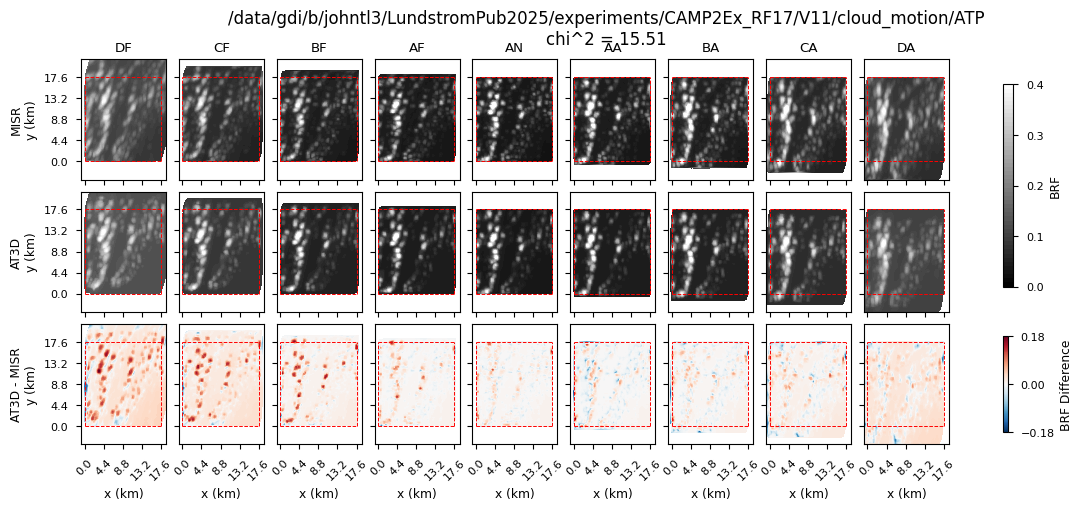

In [9]:
f, ax = plt.subplots(3, 9, figsize=(14, 5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.15, hspace=0.1)
plot_F_vs_MISR(f, ax, r, mask_name, mask_vals, plot_kwargs, diff_kwargs, contr_kwargs, comp_chi2=True, contr=False, dom_boarder=True)

In [ ]:
f, ax = plt.subplots(3, 9, figsize=(14, 5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.15, hspace=0.1)
plot_F_vs_MISR(f, ax, r, mask_name, mask_vals, plot_kwargs, diff_kwargs, contr_kwargs, comp_chi2=True, contr=True, dom_boarder=True)